In [2]:
import scimap as sm

Running SCIMAP  2.3.4


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc

In [2]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Notebook_home_250910'

## download the adata object "Xenium_Proseq_pt2_control_neighborhood_261009.h5ad" from the GitHub page"

In [4]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt2_control_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 3308 × 469
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans3'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [28]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='Cell_label_L3', method='radius', radius=80, label='spatial_lda')

Processing: ['Pt2_control_proseq']
Identifying neighbours within 80 pixels of every cell
Pre-Processing Spatial LDA
Training Spatial LDA
Calculating the Coherence Score

Coherence Score:  0.541282868507519
Gathering the latent weights


C:\Users\tpeng\anaconda3\envs\scimap\lib\site-packages\scimap\tools\spatial_lda.py:270: ImplicitModificationWarning:

Trying to modify attribute `._uns` of view, initializing view as actual.



In [35]:
adata

AnnData object with n_obs × n_vars = 3308 × 469
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## try 3 clusters ##

In [38]:
# note that the df_name parameter needs to be the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, df_name='spatial_lda', method='kmeans', k=3, label='spatial_lda_kmeans3')

Kmeans clustering


In [40]:
# Let's visualize the results.

from matplotlib import rcParams
FIGSIZE = (16, 16)
my_colors = {'0':'olive', '1':'goldenrod', '2' : 'lightsteelblue'}

sm.pl.spatial_scatterPlot(adata, colorBy='spatial_lda_kmeans3', s =4, alpha = 0.8,  dpi = 300,customColors = my_colors,
                          fileName='scatterplot_pt2_control_IC+kera_3clusters_261009.png', saveDir="./figures")

Saved plot to ./figures\scatterplot_pt2_control_IC+kera_3clusters_261009.png


In [42]:
adata.write_h5ad ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt2_control_neighborhood_261009.h5ad')

## Generate heatmap ##

In [5]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt2_control_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 3308 × 469
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans3'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [7]:
adata.obs.imageid.unique()

['Pt2_control_proseq']
Categories (1, object): ['Pt2_control_proseq']

In [9]:
df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans3"].value_counts().unstack()
df

C:\Users\tpeng\AppData\Local\Temp\ipykernel_15956\2134724537.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans3"].value_counts().unstack()


spatial_lda_kmeans3,0,1,2
Cell_label_L3,,,
Basal keratinocyte,1226,306,13
CD4 T cell_FOXP3+,4,0,21
CD4 T cell_GZMBlow,0,0,41
CD8 T cell_GZMBlow,1,1,38
DC,2,1,66
Granulosum keratinocyte_KRT2+,142,315,13
ILC,9,1,12
Langerhans cell,62,46,8
Mac_ISGlow,22,3,155


In [10]:
frequency_table = (df / df.sum())*100
pd.options.display.float_format = '{:.2f}'.format

In [11]:
# Define your desired custom order
custom_order = ['1', '0', '2']
frequency_table = frequency_table[custom_order]
frequency_table.columns = ['N0','N1','N2']
frequency_table.head(n=2)

,N0,N1,N2
Cell_label_L3,,,
Basal keratinocyte,29.28,66.92,3.02
CD4 T cell_FOXP3+,0.00,0.22,4.87


In [12]:
list2 = [
 'Granulosum keratinocyte_KRT2+',
 'Spinosum keratinocyte_KRT2+',
 'Basal keratinocyte',

 'CD8 T cell_GZMBlow','CD4 T cell_GZMBlow','CD4 T cell_FOXP3+','ILC','Mac_ISGlow','Langerhans cell','Mast cell','DC'
]

# Define your desired custom order
custom_order = list2
# Reorder the index based on the list
frequency_table = frequency_table.reindex(custom_order)
frequency_table

,N0,N1,N2
Cell_label_L3,,,
Granulosum keratinocyte_KRT2+,30.14,7.75,3.02
Spinosum keratinocyte_KRT2+,35.50,19.21,0.00
Basal keratinocyte,29.28,66.92,3.02
CD8 T cell_GZMBlow,0.10,0.05,8.82
CD4 T cell_GZMBlow,0.00,0.00,9.51
CD4 T cell_FOXP3+,0.00,0.22,4.87
ILC,0.10,0.49,2.78
Mac_ISGlow,0.29,1.20,35.96
Langerhans cell,4.40,3.38,1.86


In [13]:
frequency_table.index = [
 'Granu kera_KRT2+',
 'Spino kera_KRT2+',
 'Basal kera',

 'CD8 T_GZMBlow','CD4 T_GZMBlow','CD4 T_FOXP3+','ILC','Mac_ISGlow','Langerhans','Mast','DC'
]

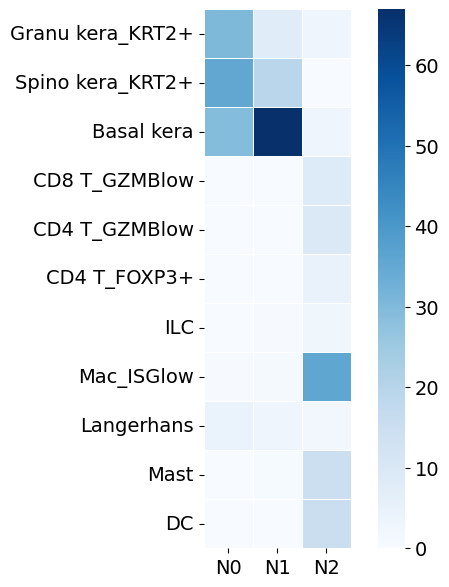

In [14]:
plt.figure(figsize=(7, 7)) # Optional: Adjust the size of the plot

ax = sns.heatmap(
    data= frequency_table,          # The DataFrame/data to plot
    annot=False,               # Display the correlation values on the heatmap
    cmap='Blues',          # The color map (e.g., 'viridis', 'plasma', 'coolwarm')
    fmt=".2f",                # String format for annotation values
    linewidths=.5,            # Space between cells
    annot_kws={"fontsize": 16}, square = True
)


# Set the font size for the x and y tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)


# Access the colorbar and set the size of its tick labels
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14) # 'labelsize' parameter sets the tick label font size

plt.show()